# Measuring SPARTAN's own HIPS curve: what the data already say, and the paired-filter experiment (24 Nov 2026)

**Proposal.** Put the same air on a light and a dark filter: two SPARTAN samplers side by side (or one sampler alternating two
slots), one running short and one full length, at the same flow. This is White et al.'s IMPROVE-versus-CSN test done inside
SPARTAN. It needs no TOR, no FTIR and no transfer from IMPROVE's screen.

This notebook places that experiment among what was already done:

| Test | Same air? | Different darkness? | Same hardware? | What it gave |
|---|---|---|---|---|
| IMPROVE groups against TOR (20 Nov) | no, different days | yes | yes | τ∞ 2.26 [1.82, 2.70], but TOR error and composition ride along |
| IMPROVE against CSN, 4 cities (24 Nov) | **yes** | **yes, about 10×** | no (SASS vs IMPROVE) | shape τ∞ 2.29, but only with IMPROVE 10 % above CSN; α 10 fits with no offset |
| Phoenix drain discs (White et al. 2025, section 5) | **yes** | no, same loading | **yes** | unpublished UC Davis data, held back until Warren agrees |
| MA350 tape advances (24 Nov, aethalometer page) | **yes** | **yes** | **yes** | the aethalometer's own k, 0.0115 at Addis IR |
| HIPS against the aethalometer at Addis (below) | yes, same days | yes | no | τ∞ ≈ 1.9, but darkness = dirty air at Addis |
| **Paired SPARTAN filters (proposed)** | **yes** | **yes** | **yes** | SPARTAN's own curve |

The paired experiment is the only one with all three: the same air, two loadings, and SPARTAN's own sampler and filter holder.


In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

ROOT = Path.cwd()
while not (ROOT / 'gallery').exists():
    ROOT = ROOT.parent
HL = ROOT / 'gallery/app/public/data/hips_linearise'
lin = json.load(open(HL / 'linearise.json'))
aeth = json.load(open(ROOT / 'gallery/app/public/data/experimental/aeth_loading_k.json'))
TINF_PUB = 2.2596
hyper = lambda x, T: x / (1 + x / T)
inv = lambda t, T: t / (1 - t / T)
addis = [f for f in lin['filters'] if f['ftir'] is not None]
tau = np.array([f['tau'] for f in addis]); bc = np.array([f['hips_bc'] for f in addis]); ec = np.array([f['ftir'] for f in addis])
vol = np.array([f['volume_m3'] for f in addis])
print(len(addis), 'Addis filters with FTIR EC')

189 Addis filters with FTIR EC


## 1. At Addis, a dark filter and a dirty day are the same thing

The loading effect depends on how much is on the filter; a composition effect depends on the air. On a SPARTAN filter the
two move together unless the sampled volume varies. At Addis it hardly does.

In [2]:
ok = np.array([f['volume_known'] for f in addis])
V = vol[ok]
print('sampled volume p5 / p50 / p95 (m3):', np.percentile(V, [5, 50, 95]).round(2), ' CV', round(V.std() / V.mean(), 3))
print('share of the variance of log tau that is volume:', round(np.var(np.log(V)) / np.var(np.log(tau[ok])), 3))
print('corr(log volume, log FTIR EC):', round(np.corrcoef(np.log(V), np.log(ec[ok]))[0, 1], 2))

sampled volume p5 / p50 / p95 (m3): [7.03 7.27 7.36]  CV 0.015
share of the variance of log tau that is volume: 0.006
corr(log volume, log FTIR EC): 0.08


So 99 % of how dark an Addis filter is comes from the air, not the volume. Nothing in the existing Addis record can tell a
loading effect from a composition effect that grows with pollution. The 3 Nov natural experiment at sites where volume varies
independently of concentration found almost no volume effect (−0.08 ± 0.08 against −0.25 predicted; see the gallery
`#xc-why`), which is the tension this experiment would settle.

## 2. HIPS against the aethalometer: Addis bends, as hard as the IMPROVE curve implies

The MA350 is now a self-calibrated reference: its loading constant from the tape-advance step (no FTIR) is 0.0115 at IR, the
same as the k that leaves BC uncorrelated with ATN (Experimental page *Aethalometer loading k*). Taking the aethalometer BC
times the filter's volume as the true loading, the HIPS optical depth should rise in proportion if HIPS were linear. The fit has
a free scale `a`, so the aethalometer's cross-section does not matter, only its linearity.

In [3]:
s = aeth['sites']['ETAD-JACROS']; grid = np.array(aeth['settings']['k_grid']); ch = s['channels']['IR']
pos = {f: i for i, f in enumerate(s['filters']['id'])}
def aeth_bc(fid, k):
    v = ch['filters']['bc_k'][pos[fid]]
    return np.interp(k, grid, np.array([np.nan if x is None else x for x in v]))

def fit_ceiling(x, t):
    f = lambda q: np.log(hyper(np.exp(q[0]) * x, np.exp(q[1]))) - np.log(t)
    return np.exp(optimize.least_squares(f, [np.log(0.1), np.log(2)], bounds=([-10, np.log(0.3)], [5, np.log(50)])).x)

rows = []
for label, k in [('aethalometer, k 0 (BC1)', 0.0), ('aethalometer, tape-step k 0.0115', 0.0115), ('aethalometer, median K 0.0123', 0.0123), ('FTIR EC', None)]:
    X, T = [], []
    for f in addis:
        if not f['volume_known']: continue
        if k is None: b = f['ftir']
        elif f['id'] in pos: b = aeth_bc(f['id'], k)
        else: continue
        if np.isfinite(b) and b > 0: X.append(b * f['volume_m3']); T.append(f['tau'])
    X, T = np.array(X), np.array(T)
    a, c = fit_ceiling(X, T)
    rng = np.random.default_rng(1)
    boot = [fit_ceiling(X[j], T[j])[1] for j in (rng.integers(0, len(X), len(X)) for _ in range(300))]
    rows.append((label, len(X), c, *np.percentile(boot, [5, 95]), np.polyfit(np.log(X), np.log(T), 1)[0]))
    if k == 0.0115: Xa, Ta, aa, ca = X, T, a, c
for r in rows: print(f'{r[0]:34s} n {r[1]}  tau_inf {r[2]:.2f} [{r[3]:.2f}, {r[4]:.2f}]  log-log slope {r[5]:.2f}')

aethalometer, k 0 (BC1)            n 168  tau_inf 1.78 [1.64, 1.90]  log-log slope 0.43
aethalometer, tape-step k 0.0115   n 168  tau_inf 1.90 [1.79, 1.99]  log-log slope 0.46
aethalometer, median K 0.0123      n 168  tau_inf 1.90 [1.79, 1.99]  log-log slope 0.46
FTIR EC                            n 189  tau_inf 1.57 [1.39, 1.75]  log-log slope 0.39


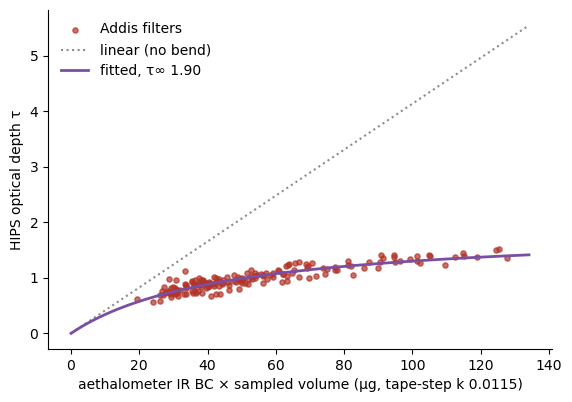

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 4.4))
ax.scatter(Xa, Ta, s=14, color='#B23327', alpha=0.7, label='Addis filters')
xx = np.linspace(0, Xa.max() * 1.05, 200)
ax.plot(xx, aa * xx, ':', color='#8F8C84', label='linear (no bend)')
ax.plot(xx, hyper(aa * xx, ca), color='#7A4FA3', lw=2, label=f'fitted, τ∞ {ca:.2f}')
ax.set_xlabel('aethalometer IR BC × sampled volume (µg, tape-step k 0.0115)'); ax.set_ylabel('HIPS optical depth τ')
ax.spines[['top', 'right']].set_visible(False); ax.legend(frameon=False); plt.show()

Against an instrument that corrects its own loading, Addis HIPS rises with a log-log slope near 0.46 (1 is linear): a
ceiling of about 1.9, at least as much bend as IMPROVE's curve. The bend is in HIPS, not FTIR. Two reasons this cannot be
the Addis ceiling:

- **It reads the bend too strong.** The x axis carries the aethalometer's own per-filter error and the real day-to-day spread
  in absorption per mass, over a narrow range (Addis τ spans about 2.5×). Errors in x steepen the apparent bend, exactly as
  grouping IMPROVE by the filter's own TOR did (1.1 to 1.9 against 2.26). FTIR EC on the same axis gives 1.57 for the same
  reason, yet FTIR against HIPS linearised at 2.26 has a zero intercept. So 1.9 is a lower bound, not an estimate.
- **It cannot separate loading from the air** (section 1): on Addis's constant volume a dark filter is a dirty day.

The paired design fixes both. The two loadings differ by a set factor r instead of by the day's pollution, and the 4 %
reading error is small against a 4× lever.

## 3. Why the ceiling is the whole question: the Addis MAC at each ceiling

FTIR EC on HIPS BC linearised at ceiling τ∞ (Deming λ 2.96 at MAC 10), and the MAC at which the slope is 1 (MAC ÷ slope).

tau_inf 1.9: MAC for slope 1  29.8, intercept +1.22
tau_inf 2.26: MAC for slope 1  18.3, intercept +0.01
tau_inf 2.7: MAC for slope 1  13.3, intercept -0.97
tau_inf 3.26: MAC for slope 1  10.4, intercept -1.82
tau_inf 4.06: MAC for slope 1   8.5, intercept -2.65


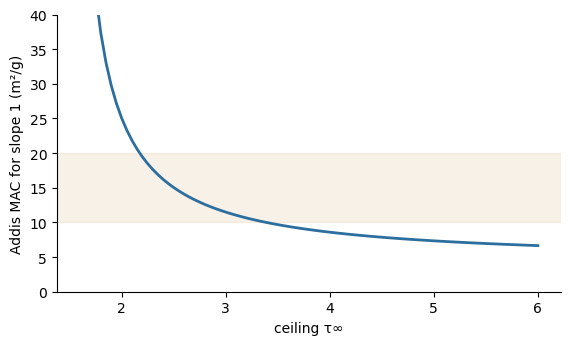

In [5]:
def deming(x, y, lam=2.96):
    mx, my = x.mean(), y.mean(); sxx = ((x - mx)**2).sum(); syy = ((y - my)**2).sum(); sxy = ((x - mx) * (y - my)).sum()
    d = syy - lam * sxx; sl = (d + np.sqrt(d * d + 4 * lam * sxy * sxy)) / (2 * sxy); return sl, my - sl * mx
Tg = np.linspace(1.6, 6, 89); MAC, ICPT = [], []
for T in Tg:
    k = 1 / (1 - tau / T); m = np.isfinite(k) & (k > 0)
    sl, b = deming(bc[m] * k[m], ec[m]); MAC.append(10 / sl); ICPT.append(b)
MAC, ICPT = np.array(MAC), np.array(ICPT)
for T in (1.9, 2.26, 2.7, 3.26, 4.06):
    print(f'tau_inf {T}: MAC for slope 1 {np.interp(T, Tg, MAC):5.1f}, intercept {np.interp(T, Tg, ICPT):+.2f}')
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(Tg, MAC, color='#2C6E9E', lw=2); ax.set_ylim(0, 40); ax.axhspan(10, 20, color='#C49442', alpha=0.12)
ax.set_xlabel('ceiling τ∞'); ax.set_ylabel('Addis MAC for slope 1 (m²/g)')
ax.spines[['top', 'right']].set_visible(False); plt.show()

Between τ∞ 2.26 and 3.3 the MAC runs from 18 to 10: the "10 to 20" range is entirely the ceiling. Below 2 the MAC
climbs past 30 and the intercept turns positive (over-correction).

## 4. How many paired filters the experiment needs

Simulation. Dark filters are drawn from the Addis optical depths (24 h runs); the light filter of each pair sees the same air
for 1/r of the time, so its true loading is 1/r of the dark one's. Both are read with 4 % random error per filter (the HIPS
precision from IMPROVE's collocated Phoenix pairs, 3.7 to 4.4 %), and the ceiling is fitted from the pairs alone: the light
filter's τ predicts the dark one's through the curve. Then the ceiling is turned into a MAC with section 3.

In [6]:
def fit_pairs(tl, td, r):
    def res(q):
        T = np.exp(q[0]); xl = np.where(tl < T, inv(tl, T), np.nan)
        out = np.log(hyper(r * xl, T)) - np.log(td); out[~np.isfinite(out)] = 5; return out
    return np.exp(optimize.least_squares(res, [np.log(2.5)], bounds=([np.log(0.8)], [np.log(60)])).x[0])

rng = np.random.default_rng(7); SD = 0.04
res = {}
for T_true in (1.9, 2.26, 3.26):
    for r in (2, 4, 8):
        for n in (5, 10, 20, 40):
            est = []
            for _ in range(400):
                td_t = np.minimum(rng.choice(tau, n), 0.95 * T_true)
                tl_t = hyper(inv(td_t, T_true) / r, T_true)
                est.append(fit_pairs(tl_t * np.exp(rng.normal(0, SD, n)), td_t * np.exp(rng.normal(0, SD, n)), r))
            q = np.percentile(est, [5, 50, 95]); res[(T_true, r, n)] = (q, np.interp(q, Tg, MAC))
print('true tau_inf  r   n   fitted tau_inf [5, 95]     Addis MAC [5, 95]')
for (T_true, r, n), (q, m) in res.items():
    if r == 4 or n == 20:
        print(f'{T_true:8}    {r}  {n:3d}   {q[1]:.2f} [{q[0]:.2f}, {q[2]:.2f}]        {m[1]:5.1f} [{m[2]:.1f}, {m[0]:.1f}]')

true tau_inf  r   n   fitted tau_inf [5, 95]     Addis MAC [5, 95]
     1.9    2   20   1.90 [1.77, 2.02]         29.9 [24.3, 41.3]
     1.9    4    5   1.89 [1.73, 2.05]         30.2 [23.3, 46.2]
     1.9    4   10   1.90 [1.79, 2.01]         29.8 [24.6, 38.6]
     1.9    4   20   1.90 [1.82, 1.98]         29.9 [26.1, 35.6]
     1.9    4   40   1.90 [1.84, 1.96]         30.0 [26.8, 33.7]
     1.9    8   20   1.90 [1.83, 1.97]         29.9 [26.2, 34.8]
    2.26    2   20   2.26 [2.10, 2.47]         18.4 [15.4, 21.9]
    2.26    4    5   2.26 [2.05, 2.53]         18.3 [14.8, 23.3]
    2.26    4   10   2.25 [2.11, 2.44]         18.5 [15.7, 21.5]
    2.26    4   20   2.25 [2.14, 2.39]         18.5 [16.4, 20.7]
    2.26    4   40   2.25 [2.17, 2.34]         18.4 [17.0, 20.1]
    2.26    8   20   2.26 [2.17, 2.35]         18.4 [16.9, 20.2]
    3.26    2   20   3.24 [2.91, 3.71]         10.5 [9.2, 12.0]
    3.26    4    5   3.27 [2.83, 3.89]         10.4 [8.8, 12.4]
    3.26    4   10   3.25

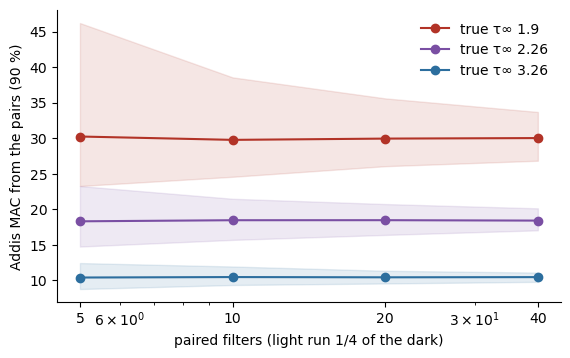

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for T_true, c in ((1.9, '#B23327'), (2.26, '#7A4FA3'), (3.26, '#2C6E9E')):
    ns = [5, 10, 20, 40]; m = [res[(T_true, 4, n)][1] for n in ns]
    ax.plot(ns, [x[1] for x in m], marker='o', color=c, label=f'true τ∞ {T_true}')
    ax.fill_between(ns, [x[2] for x in m], [x[0] for x in m], color=c, alpha=0.12)
ax.set_xscale('log'); ax.set_xticks([5, 10, 20, 40]); ax.set_xticklabels(['5', '10', '20', '40'])
ax.set_xlabel('paired filters (light run 1/4 of the dark)'); ax.set_ylabel('Addis MAC from the pairs (90 %)')
ax.spines[['top', 'right']].set_visible(False); ax.legend(frameon=False); plt.show()

Twenty pairs at a 4× ratio pin the ceiling to about ±5 % and the Addis MAC to about ±1 (if the truth is near 10) to ±2
(near 18). Ten pairs already separate MAC 10 from MAC 18. A ratio of 2 is weaker; 4 to 8 are about the same.

What the simulation leaves out, and the design should guard against:

- **Vary duration, not flow.** A lower flow lowers face velocity, and White et al. (2025, p. 225) say the deposit pattern
  depends on it. Same flow and holder, shorter time, gives the same pattern at two loadings.
- **Same air in time.** A short run inside the long one samples only part of the day. Either alternate the light filter in
  short slots spread through the whole period (if the SS5 can switch slots within a day), or use a second sampler running
  a duty cycle across the same 24 h.
- **The light filter needs no correction to be useful.** At τ 0.3 the curve's correction is ×1.15 at τ∞ 2.26 and ×1.10 at
  3.26, so the pair measures the dark filter's correction almost directly: factor ≈ r · τ_light / τ_dark. That is a
  model-free reading at each dark filter's τ, as well as the fitted ceiling.
- **Cover the Addis range.** Dark filters from τ 0.6 to 1.5 (the Addis 5 to 95 %); seasons with charcoal and without, so a
  composition effect would show up as pairs that disagree by season.
- **Blanks and volumes.** Volume errors enter the ratio directly; log both samplers' flows. Field blanks on both.
- **What it still won't give.** The pairs fix the HIPS correction. The MAC then comes from FTIR EC (or the aethalometer)
  against corrected HIPS, so it is a MAC relative to that reference.
